In [1]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [3]:
# Load the cleaned datasets
df_benin = pd.read_csv('data/Benin_clean.csv')
df_sierraleone = pd.read_csv('data/sierraleone_clean.csv')
df_togo = pd.read_csv('data/Togo_clean.csv')

In [4]:

# Add country identifier to each DataFrame
df_benin['country'] = 'Benin'
df_sierraleone['country'] = 'Sierra Leone'
df_togo['country'] = 'Togo'

In [5]:
# Concatenate the DataFrames for easier plotting and analysis
df_all = pd.concat([df_benin, df_sierraleone, df_togo], ignore_index=True)

/tmp/ipykernel_12809/3006407729.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_all, x='country', y=metric, palette='Set3')


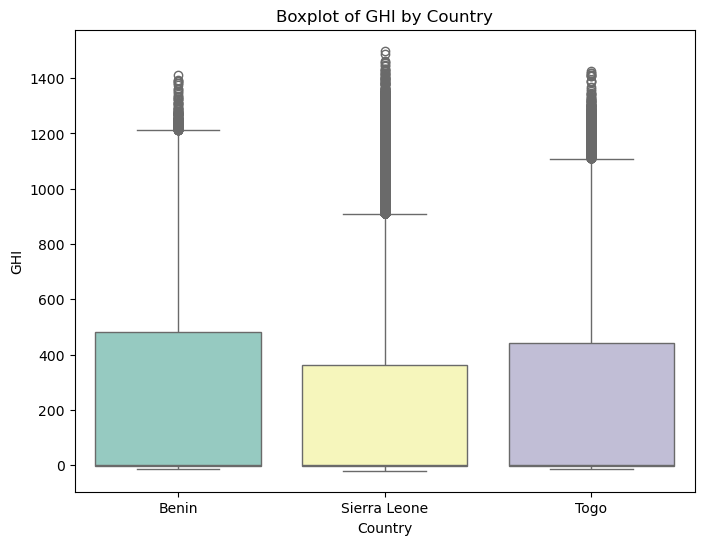

/tmp/ipykernel_12809/3006407729.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_all, x='country', y=metric, palette='Set3')


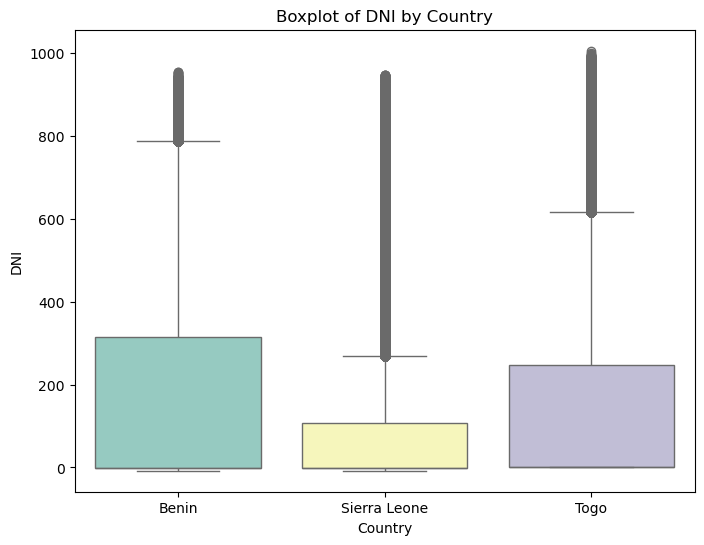

/tmp/ipykernel_12809/3006407729.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_all, x='country', y=metric, palette='Set3')


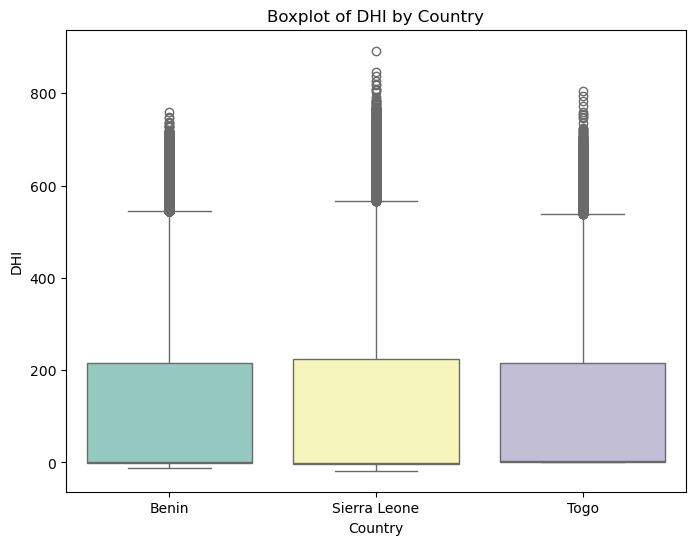

In [6]:
# Metric Comparison: Boxplots
for metric in ['GHI', 'DNI', 'DHI']:
    plt.figure(figsize=(8, 6))
    sns.boxplot(data=df_all, x='country', y=metric, palette='Set3')
    plt.title(f'Boxplot of {metric} by Country')
    plt.xlabel('Country')
    plt.ylabel(metric)
    plt.show()

In [7]:
# Summary Table: Mean, Median, Std of GHI, DNI, DHI by country
summary = df_all.groupby('country')[['GHI', 'DNI', 'DHI']].agg(['mean', 'median', 'std'])
print("Summary Table:")
print(summary)

Summary Table:
                     GHI                            DNI                     \
                    mean median         std        mean median         std   
country                                                                      
Benin         240.559452    1.8  331.131327  167.187516   -0.1  261.710501   
Sierra Leone  201.957515    0.3  298.495150  116.376337   -0.1  218.652659   
Togo          230.555040    2.1  322.532347  151.258469    0.0  250.956962   

                     DHI                     
                    mean median         std  
country                                      
Benin         115.358961    1.6  158.691074  
Sierra Leone  113.720571   -0.1  158.946032  
Togo          116.444352    2.5  156.520714  


In [8]:
# Statistical Testing: One-way ANOVA on GHI
ghi_benin = df_benin['GHI']
ghi_sierraleone = df_sierraleone['GHI']
ghi_togo = df_togo['GHI']

f_stat, p_val = stats.f_oneway(ghi_benin, ghi_sierraleone, ghi_togo)
print(f"\nOne-way ANOVA for GHI: F-statistic = {f_stat:.4f}, p-value = {p_val:.4e}")


One-way ANOVA for GHI: F-statistic = 2090.0929, p-value = 0.0000e+00


Kruskal-Wallis for GHI: H-statistic = 4524.8835, p-value = 0.0000e+00


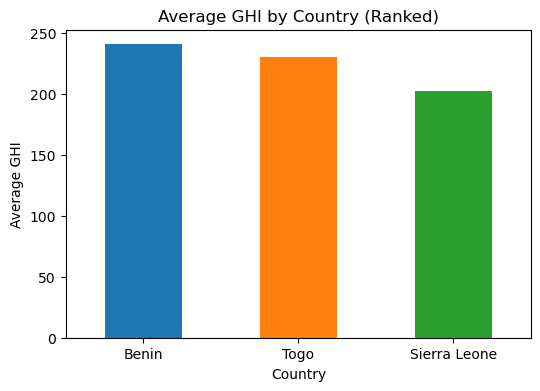

In [10]:












# Alternative: Kruskal-Wallis test (non-parametric)
k_stat, k_p_val = stats.kruskal(ghi_benin, ghi_sierraleone, ghi_togo)
print(f"Kruskal-Wallis for GHI: H-statistic = {k_stat:.4f}, p-value = {k_p_val:.4e}")

# (Bonus) Visual Summary: Bar chart ranking countries by average GHI
avg_ghi = df_all.groupby('country')['GHI'].mean().sort_values(ascending=False)
plt.figure(figsize=(6, 4))
avg_ghi.plot(kind='bar', color=['#1f77b4', '#ff7f0e', '#2ca02c'])
plt.title('Average GHI by Country (Ranked)')
plt.xlabel('Country')
plt.ylabel('Average GHI')
plt.xticks(rotation=0)
plt.show()